# ============================================
# KAGGLE NOTEBOOK: Mask R-CNN + EfficientNetB3
# FoodSeg103 → Pseudo Instance → Training
# ============================================

## 1. Install Dependencies

In [ ]:
!pip install -q torchvision opencv-python

## 2. Imports

In [ ]:
import os
import numpy as np
import cv2
import torch
import torchvision
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.transforms import functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
import tensorflow as tf

## 3. Configuration

In [ ]:
DEVICE = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
DATA_DIR = "/kaggle/input/datasets/ggrill/foodseg103/FoodSeg103/Images"  # Change if needed

## 4. Dataset Class

In [ ]:
class FoodSegDataset(Dataset):
    def __init__(self, img_dir, mask_dir):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.images = sorted(os.listdir(img_dir))
        self.masks = sorted(os.listdir(mask_dir))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.images[idx])
        mask_path = os.path.join(self.mask_dir, self.masks[idx])

        img = Image.open(img_path).convert("RGB")
        mask = np.array(Image.open(mask_path))

        # Convert semantic mask → pseudo instances
        obj_ids = np.unique(mask)
        obj_ids = obj_ids[obj_ids != 0]

        masks = mask == obj_ids[:, None, None]

        boxes = []
        final_masks = []

        for i in range(len(obj_ids)):
            pos = np.where(masks[i])
            if pos[0].size == 0:
                continue
            xmin = np.min(pos[1])
            xmax = np.max(pos[1])
            ymin = np.min(pos[0])
            ymax = np.max(pos[0])

            if (xmax - xmin) < 5 or (ymax - ymin) < 5:
                continue

            boxes.append([xmin, ymin, xmax, ymax])
            final_masks.append(masks[i])

        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            final_masks = torch.zeros((0, mask.shape[0], mask.shape[1]), dtype=torch.uint8)
        else:
            boxes = torch.as_tensor(boxes, dtype=torch.float32)
            final_masks = torch.as_tensor(np.array(final_masks), dtype=torch.uint8)

        labels = torch.ones((len(boxes),), dtype=torch.int64)  # single class: food

        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        target["masks"] = final_masks
        target["image_id"] = torch.tensor([idx])

        img = F.to_tensor(img)

        return img, target

## 5. Load Data & Initialize Model

In [ ]:
train_dataset = FoodSegDataset(
    img_dir=os.path.join(DATA_DIR, "img_dir", "train"),
    mask_dir=os.path.join(DATA_DIR, "ann_dir", "train")
)

train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True, collate_fn=lambda x: tuple(zip(*x)))

model = maskrcnn_resnet50_fpn(pretrained=True)

# Modify head for 2 classes (background + food)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(in_features, 2)

in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
hidden_layer = 256
model.roi_heads.mask_predictor = torchvision.models.detection.mask_rcnn.MaskRCNNPredictor(in_features_mask, hidden_layer, 2)

model.to(DEVICE)

## 6. Training Loop

In [ ]:
from tqdm import tqdm

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(params, lr=1e-4)

EPOCHS = 3

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    
    loop = tqdm(train_loader, leave=True)
    
    for images, targets in loop:
        images = list(img.to(DEVICE) for img in images)
        targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        total_loss += losses.item()
        
        loop.set_description(f"Epoch [{epoch+1}/{EPOCHS}]")
        loop.set_postfix(loss=losses.item())

    print(f"End of Epoch {epoch+1}, Total Loss: {total_loss}")
    
    # NEW: Save a checkpoint at the end of EVERY epoch
    save_path = f"maskrcnn_food_epoch_{epoch+1}.pth"
    torch.save(model.state_dict(), save_path)
    print(f"Saved backup: {save_path}\n")


## 7. Inference Pipeline (Detecting newly added item)
This function compares the old plate with the new plate to isolate the newly added food item using Mask R-CNN refinement.

In [ ]:
# def get_new_item(prev_img, curr_img, model):,.
#     # Assuming prev_img and curr_img are standard RGB numpy arrays (e.g. loaded with matplotlib or PIL)
#     model.eval()

#     # Convert to grayscale to find the difference
#     prev = cv2.cvtColor(prev_img, cv2.COLOR_RGB2GRAY) # FIXED: Use RGB2GRAY to match model training colors
#     curr = cv2.cvtColor(curr_img, cv2.COLOR_RGB2GRAY)

#     diff = cv2.absdiff(curr, prev)
#     _, thresh = cv2.threshold(diff, 25, 255, cv2.THRESH_BINARY)

#     kernel = np.ones((3,3), np.uint8)
#     thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

#     x, y, w, h = cv2.boundingRect(thresh)
#     crop = curr_img[y:y+h, x:x+w]
    
#     if crop.size == 0:
#         print("No difference detected.")
#         return curr_img

#     img_tensor = F.to_tensor(Image.fromarray(crop)).unsqueeze(0).to(DEVICE)

#     with torch.no_grad():
#         output = model(img_tensor)[0]

#     if len(output['masks']) > 0:
#         mask = output['masks'][0, 0].cpu().numpy()
#         mask = (mask > 0.5).astype(np.uint8)
#         crop[mask == 0] = 0

#     return crop

## 8. Classification Pipeline (EfficientNetB3)

In [ ]:
# # Load your trained Indian Food classifier
# classifier = load_model('/kaggle/input/datasets/dheerajmalavath/indian-food-model-v2-keras/indian_food_model_v2.keras') # Update path if necessary

# # This list should match the 80 classes your model was trained on.
# class_labels = [
#     "adhirasam", "aloo_gobi", "aloo_matar", "aloo_methi", "aloo_shimla_mirch", 
#     "aloo_tikki", "anarsa", "ariselu", "bandar_laddu", "basundi", 
#     "bhatura", "bhindi_masala", "biryani", "boondi", "butter_chicken", 
#     "chak_hao_kheer", "cham_cham", "chana_masala", "chapati", "chhena_kheeri", 
#     "chicken_razala", "chicken_tikka", "chicken_tikka_masala", "chikki", "daal_baati_churma", 
#     "daal_puri", "dal_makhani", "dal_tadka", "dharwad_pedha", "doodhpak", 
#     "double_ka_meetha", "dum_aloo", "gajar_ka_halwa", "gavvalu", "ghevar", 
#     "gulab_jamun", "imarti", "jalebi", "kachori", "kadai_paneer", 
#     "kadhi_pakoda", "kajjikaya", "kakinada_khaja", "kalakand", "karela_bharta", 
#     "kofta", "kuzhi_paniyaram", "lassi", "ledikeni", "litti_chokha", 
#     "lyangcha", "maach_jhol", "makki_di_roti_sarson_da_saag", "malapua", "misi_roti", 
#     "misti_doi", "modak", "mysore_pak", "naan", "navrattan_korma", 
#     "palak_paneer", "paneer_butter_masala", "phirni", "pithe", "poha", 
#     "poornalu", "pootharekulu", "qubani_ka_meetha", "rabri", "ras_malai", 
#     "rasgulla", "sandesh", "shankarpali", "sheer_korma", "sheera", 
#     "shrikhand", "sohan_halwa", "sohan_papdi", "sutar_feni", "unni_appam"
# ]
#  # You will need to replace this with your actual list of 80 food names

# def classify(image):
#     # Resize to the shape EfficientNet expects
#     img = cv2.resize(image, (300, 300)) 
    
#     # FIXED: Removed 'img = img / 255.0' because EfficientNet expects raw 0-255 pixels!
    
#     img = np.expand_dims(img, axis=0)

#     preds = classifier.predict(img, verbose=0)
#     class_index = np.argmax(preds)
    
#     # Map index to actual food name if we have the labels, otherwise return the raw index
#     if len(class_labels) >= 80:
#         return class_labels[class_index]
#     else:
#         return f"Class ID {class_index}"

## 9. Full Step Pipeline
Combines inference and classification.

In [ ]:
# def process_step(prev_img, curr_img, prev_w, curr_w):
#     # 1. Isolate the new item using Mask R-CNN
#     new_item_img = get_new_item(prev_img, curr_img, model)
    
#     # 2. Classify the isolated item using EfficientNetB3
#     label = classify(new_item_img)
    
#     # 3. Weight calculation (currently suspended/commented out per instructions)
#     # weight = curr_w - prev_w
#     weight = "Calculation Suspended" 

#     return label, weight

In [ ]:
# Run this if you cancel the training early!
torch.save(model.state_dict(), "maskrcnn_emergency_save.pth")
print("Emergency manual save complete!")


In [ ]:
# 1. Show the blueprint for the TensorFlow/Keras EfficientNet model
print("=== EFFICIENTNET CLASSIFIER SUMMARY ===")
classifier.summary()

# 2. Show the blueprint for the PyTorch Mask R-CNN model
print("\n=== MASK R-CNN SUMMARY ===")
print(model)


In [ ]:
from IPython.display import FileLink

# This will create a clickable download link for your final epoch!
FileLink(r'maskrcnn_food_epoch_3.pth')


In [ ]:
# import cv2
# import matplotlib.pyplot as plt

# # 1. Provide the paths to your two test images
# prev_image_path = "/kaggle/input/your-folder-name/plate_before.jpg" # CHANGE THIS PATH
# curr_image_path = "/kaggle/input/your-folder-name/plate_after.jpg"  # CHANGE THIS PATH

# # Read the images using OpenCV
# prev_img_bgr = cv2.imread(prev_image_path)
# curr_img_bgr = cv2.imread(curr_image_path)

# if prev_img_bgr is None or curr_img_bgr is None:
#     print("Error: Could not load images. Please double check your file paths!")
# else:
#     # 2. Convert from OpenCV's default BGR colors to standard RGB colors
#     prev_img_rgb = cv2.cvtColor(prev_img_bgr, cv2.COLOR_BGR2RGB)
#     curr_img_rgb = cv2.cvtColor(curr_img_bgr, cv2.COLOR_BGR2RGB)

#     # 3. Run your complete pipeline! 
#     # (We pass 0 for the weights since that feature is currently suspended)
#     predicted_food, weight_calc = process_step(prev_img_rgb, curr_img_rgb, 0, 0)

#     print("====================================")
#     print(f"AI PIPELINE DETECTED: {predicted_food}")
#     print("====================================")

#     # 4. Let's actually visualize what the Mask R-CNN isolated!
#     isolated_crop = get_new_item(prev_img_rgb, curr_img_rgb, model)
    
#     plt.figure(figsize=(6, 6))
#     plt.imshow(isolated_crop)
#     plt.title(f"Mask R-CNN Crop -> Classified as: {predicted_food}")
#     plt.axis('off')
#     plt.show()


In [ ]:
import torch
import torchvision
from torchvision.models.detection import maskrcnn_resnet50_fpn

DEVICE = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

# 1. Rebuild the blank architecture
model = maskrcnn_resnet50_fpn(pretrained=False) # False because we are loading our own weights!

# Rebuild our custom 2-class head
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(in_features, 2)
in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
model.roi_heads.mask_predictor = torchvision.models.detection.mask_rcnn.MaskRCNNPredictor(in_features_mask, 256, 2)

# 2. Load your saved weights! 
# (Make sure this path points exactly to where your epoch_3.pth file is)
SAVED_MODEL_PATH = "/kaggle/input/datasets/dheerajmalavath/maskrcnn-food-epoch/maskrcnn_food_epoch_3.pth"

model.load_state_dict(torch.load(SAVED_MODEL_PATH, map_location=DEVICE))
model.to(DEVICE)
model.eval() # Puts the model in "Inference Mode"

print("Saved model successfully loaded into memory!")


In [ ]:
# # 1. Install the torchinfo library
# !pip install -q torchinfo
# from torchinfo import summary
# import torch

# # 2. Create a "dummy" blank image to pass through the model so it can calculate the shapes
# # Notice the double brackets!
# dummy_image = [ [torch.rand(3, 300, 300).to(DEVICE)] ] 



# # 3. Print the Keras-style summary table!
# print("=== MASK R-CNN DETAILED SUMMARY ===")
# summary(model, input_data=dummy_image, 
#         col_names=["input_size", "output_size", "num_params", "kernel_size"], 
#         row_settings=["depth", "var_names"],
#         depth=4) # Depth=4 makes it expand inside the ResNet blocks


In [ ]:
# import torch
# import pandas as pd
# from torchinfo import summary
# from IPython.display import display

# # 1. Create the dummy image
# dummy_image = [ [torch.rand(3, 300, 300).to(DEVICE)] ] 

# # 2. Run the summary, but set verbose=0 so it DOES NOT print the ugly text wall
# model_stats = summary(model, input_data=dummy_image, depth=4, verbose=0)

# # 3. Extract the raw hierarchical data
# table_data = []
# for layer in model_stats.summary_list:
#     # Add spaces based on the 'depth' to keep the tree-like structure!
#     indent = "   " * layer.depth
#     layer_name = f"{indent}└─ {layer.class_name} ({layer.var_name})"
    
#     table_data.append({
#         "Network Layer": layer_name,
#         "Input Shape": str(layer.input_size),
#         "Output Shape": str(layer.output_size),
#         "Parameters": f"{layer.num_params:,}" # Format with commas
#     })

# # 4. Convert it into a Pandas DataFrame
# df_summary = pd.DataFrame(table_data)

# # 5. Tell Kaggle to render the beautiful interactive table!
# display(df_summary)


In [ ]:
# # 1. Save the table to a CSV file in Kaggle's working directory
# # The 'utf-8-sig' forces Excel to read the special tree symbols correctly!
# df_summary.to_csv("maskrcnn_summary.csv", index=False, encoding='utf-8-sig')

# # 2. Generate the clickable download link!
# from IPython.display import FileLink
# FileLink(r'maskrcnn_summary.csv')


In [ ]:
# import pandas as pd
# from tensorflow.keras.models import load_model
# from IPython.display import display, FileLink

# # 1. Reload the model
# model_path = '/kaggle/input/datasets/dheerajmalavath/indian-food-model-v2-keras/indian_food_model_v2.keras'
# classifier = load_model(model_path)

# table_data = []

# # 2. Loop through every layer safely
# for layer in classifier.layers:
    
#     # Safely hunt for the Input Shape
#     try:
#         in_shape = str(layer.input_shape)
#     except Exception:
#         try:
#             in_shape = str(layer.input.shape)
#         except Exception:
#             in_shape = "N/A"

#     # Safely hunt for the Output Shape
#     try:
#         out_shape = str(layer.output_shape)
#     except Exception:
#         try:
#             out_shape = str(layer.output.shape)
#         except Exception:
#             out_shape = "N/A"
            
#     table_data.append({
#         "Network Layer": f"{layer.__class__.__name__} ({layer.name})",
#         "Input Shape": in_shape,
#         "Output Shape": out_shape,
#         "Parameters": f"{layer.count_params():,}" 
#     })

# # 3. Convert to Pandas DataFrame
# df_classifier_summary = pd.DataFrame(table_data)

# # 4. Display the beautiful table in Kaggle
# display(df_classifier_summary)

# # 5. Save it to CSV (with the utf-8-sig fix for Excel)
# df_classifier_summary.to_csv("efficientnet_summary.csv", index=False, encoding='utf-8-sig')

# # 6. Generate the download link
# FileLink(r'efficientnet_summary.csv')


In [ ]:
# df_classifier_summary

Loading Mask R-CNN...
Loading EfficientNet...
Running Pipeline on Test Images...
AI PIPELINE DETECTED: aloo_matar


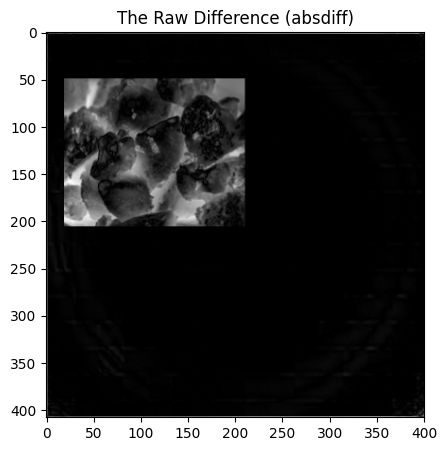

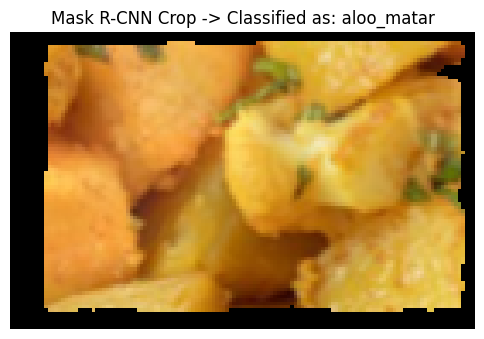

In [14]:
import os
import cv2
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.transforms import functional as F
from tensorflow.keras.models import load_model

# ==============================================================================
# 1. UPDATE THESE 5 PATHS BEFORE RUNNING!
# ==============================================================================
PREV_IMG_PATH = "/kaggle/input/datasets/dheerajmalavath/images/images/plate.png"
CURR_IMG_PATH = "/kaggle/input/datasets/dheerajmalavath/images/images/prev.png"
MASKRCNN_PATH = "/kaggle/input/datasets/dheerajmalavath/maskrcnn-food-epoch/maskrcnn_food_epoch_3.pth"
EFFICIENTNET_PATH = "/kaggle/input/datasets/dheerajmalavath/indian-food-model-v2-keras/indian_food_model_v2.keras"
LABELS_PATH = "/kaggle/input/datasets/iamsouravbanerjee/indian-food-images-dataset/List of Indian Foods.txt"
# ==============================================================================

DEVICE = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

# --- 1. LOAD MASK R-CNN ---
print("Loading Mask R-CNN...")
model = maskrcnn_resnet50_fpn(pretrained=False, pretrained_backbone=False)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(in_features, 2)
in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
model.roi_heads.mask_predictor = torchvision.models.detection.mask_rcnn.MaskRCNNPredictor(in_features_mask, 256, 2)
model.load_state_dict(torch.load(MASKRCNN_PATH, map_location=DEVICE))
model.to(DEVICE)
model.eval()

# --- 2. LOAD EFFICIENTNET & CLASSES ---
print("Loading EfficientNet...")
classifier = load_model(EFFICIENTNET_PATH)

with open(LABELS_PATH, "r") as f:
    class_labels = [line.strip() for line in f.readlines() if line.strip()]

# --- 3. DEFINE PIPELINE FUNCTIONS ---
def get_new_item(prev_img, curr_img, model):
    curr_img = cv2.resize(curr_img, (prev_img.shape[1], prev_img.shape[0]))
    
    prev = cv2.cvtColor(prev_img, cv2.COLOR_RGB2GRAY)
    curr = cv2.cvtColor(curr_img, cv2.COLOR_RGB2GRAY)
    
    diff = cv2.absdiff(curr, prev)
    _, thresh = cv2.threshold(diff, 25, 255, cv2.THRESH_BINARY)
    kernel = np.ones((3,3), np.uint8)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
    
    # === NEW FIX ===
    # Find all the separate "islands" of differences
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if not contours:
        return curr_img # No differences found at all
        
    # Find the largest island (this completely ignores the noisy Aloo Gobi edges!)
    largest_contour = max(contours, key=cv2.contourArea)
    
    # Draw a tight box around ONLY the newly added food
    x, y, w, h = cv2.boundingRect(largest_contour)
    # ===============
    
    crop = curr_img[y:y+h, x:x+w]
    
    if crop.size == 0: 
        return curr_img
        
    img_tensor = F.to_tensor(Image.fromarray(crop)).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        output = model(img_tensor)[0]
        
    if len(output['masks']) > 0:
        mask = output['masks'][0, 0].cpu().numpy()
        mask = (mask > 0.5).astype(np.uint8)
        crop[mask == 0] = 0
    return crop



def classify(image):
    img = cv2.resize(image, (300, 300)) 
    img = np.expand_dims(img, axis=0)
    preds = classifier.predict(img, verbose=0)
    return class_labels[np.argmax(preds)]

def process_step(prev_img, curr_img):
    new_item_img = get_new_item(prev_img, curr_img, model)
    label = classify(new_item_img)
    return label, new_item_img

# --- 4. RUN THE TEST ON YOUR IMAGES ---
print("Running Pipeline on Test Images...")
# Load images and convert to RGB
prev_img_rgb = cv2.cvtColor(cv2.imread(PREV_IMG_PATH), cv2.COLOR_BGR2RGB)
curr_img_rgb = cv2.cvtColor(cv2.imread(CURR_IMG_PATH), cv2.COLOR_BGR2RGB)

# Execute the pipeline!
predicted_food, isolated_crop = process_step(prev_img_rgb, curr_img_rgb)

# --- 5. DISPLAY RESULTS ---
print("====================================")
print(f"AI PIPELINE DETECTED: {predicted_food}")
print("====================================")

prev_img = cv2.cvtColor(cv2.imread(PREV_IMG_PATH), cv2.COLOR_RGB2GRAY)
curr_img = cv2.cvtColor(cv2.imread(CURR_IMG_PATH), cv2.COLOR_RGB2GRAY)

# Resize just like our pipeline does
curr_img = cv2.resize(curr_img, (prev_img.shape[1], prev_img.shape[0]))

# Calculate the difference
diff = cv2.absdiff(curr_img, prev_img)
_, thresh = cv2.threshold(diff, 25, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(10, 5))
plt.plot(1, 2, 1)
plt.title("The Raw Difference (absdiff)")
plt.imshow(diff, cmap='gray')

# Plot the isolated crop
plt.figure(figsize=(6, 6))
plt.imshow(isolated_crop)
plt.title(f"Mask R-CNN Crop -> Classified as: {predicted_food}")
plt.axis('off')
plt.show()


AI PIPELINE DETECTED: ariselu


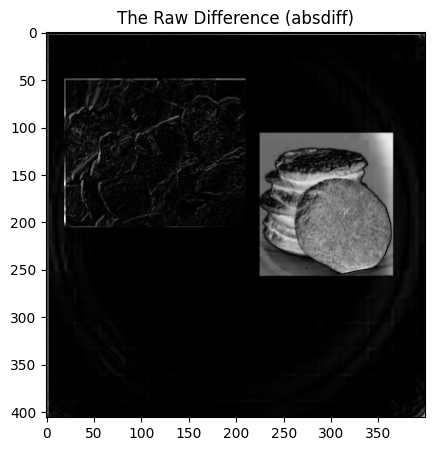

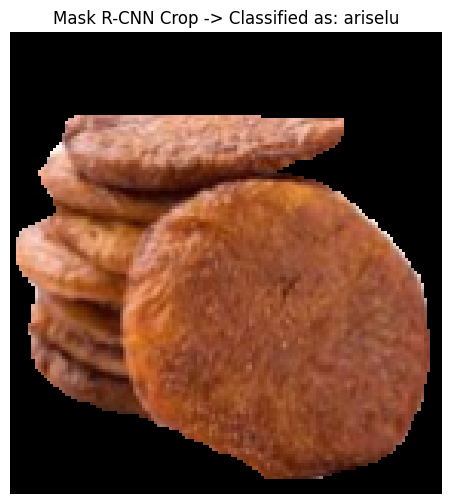

In [15]:
# 1. Define your new paths
NEW_PREV_IMG_PATH = "/kaggle/input/datasets/dheerajmalavath/images/images/prev.png" # Update this
NEW_CURR_IMG_PATH = "/kaggle/input/datasets/dheerajmalavath/images/images/cur.png" # Update this

# 2. Load the new images and convert to RGB
new_prev_img_rgb = cv2.cvtColor(cv2.imread(NEW_PREV_IMG_PATH), cv2.COLOR_BGR2RGB)
new_curr_img_rgb = cv2.cvtColor(cv2.imread(NEW_CURR_IMG_PATH), cv2.COLOR_BGR2RGB)

# 3. Execute the pipeline using the ALREADY LOADED models and functions!
predicted_food, isolated_crop = process_step(new_prev_img_rgb, new_curr_img_rgb)

# 4. Display results
print("====================================")
print(f"AI PIPELINE DETECTED: {predicted_food}")
print("====================================")

prev_img1 = cv2.cvtColor(cv2.imread(NEW_PREV_IMG_PATH), cv2.COLOR_RGB2GRAY)
curr_img1 = cv2.cvtColor(cv2.imread(NEW_CURR_IMG_PATH), cv2.COLOR_RGB2GRAY)

# Resize just like our pipeline does
curr_img1 = cv2.resize(curr_img1, (prev_img1.shape[1], prev_img1.shape[0]))

# Calculate the difference
diff1 = cv2.absdiff(curr_img1, prev_img1)
_, thresh = cv2.threshold(diff1, 25, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(10, 5))
plt.plot(1, 2, 1)
plt.title("The Raw Difference (absdiff)")
plt.imshow(diff1, cmap='gray')



# Plot the isolated crop
plt.figure(figsize=(6, 6))
plt.imshow(isolated_crop)
plt.title(f"Mask R-CNN Crop -> Classified as: {predicted_food}")
plt.axis('off')
plt.show()


AI PIPELINE DETECTED: dharwad_pedha


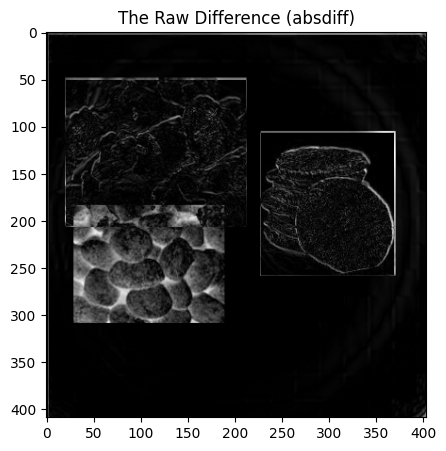

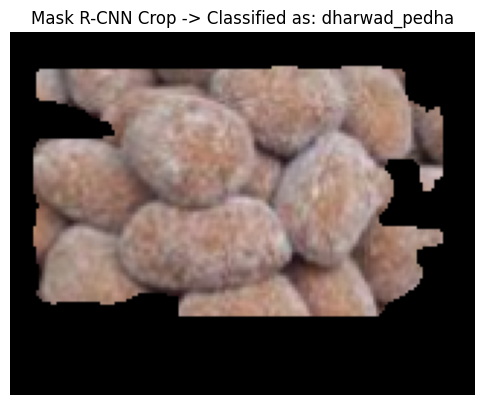

In [16]:
# 1. Define your new paths
NEW_PREV_IMG_PATH_1 = "/kaggle/input/datasets/dheerajmalavath/images/images/cur.png" # Update this
NEW_CURR_IMG_PATH_1 = "/kaggle/input/datasets/dheerajmalavath/overlap/img3(overlap).png" # Update this

# 2. Load the new images and convert to RGB
new_prev_img_rgb = cv2.cvtColor(cv2.imread(NEW_PREV_IMG_PATH_1), cv2.COLOR_BGR2RGB)
new_curr_img_rgb = cv2.cvtColor(cv2.imread(NEW_CURR_IMG_PATH_1), cv2.COLOR_BGR2RGB)

# 3. Execute the pipeline using the ALREADY LOADED models and functions!
predicted_food, isolated_crop = process_step(new_prev_img_rgb, new_curr_img_rgb)

# 4. Display results
print("====================================")
print(f"AI PIPELINE DETECTED: {predicted_food}")
print("====================================")

prev_img1 = cv2.cvtColor(cv2.imread(NEW_PREV_IMG_PATH_1), cv2.COLOR_RGB2GRAY)
curr_img1 = cv2.cvtColor(cv2.imread(NEW_CURR_IMG_PATH_1), cv2.COLOR_RGB2GRAY)

# Resize just like our pipeline does
curr_img1 = cv2.resize(curr_img1, (prev_img1.shape[1], prev_img1.shape[0]))

# Calculate the difference
diff1 = cv2.absdiff(curr_img1, prev_img1)
_, thresh = cv2.threshold(diff1, 25, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(10, 5))
plt.plot(1, 2, 1)
plt.title("The Raw Difference (absdiff)")
plt.imshow(diff1, cmap='gray')



# Plot the isolated crop
plt.figure(figsize=(6, 6))
plt.imshow(isolated_crop)
plt.title(f"Mask R-CNN Crop -> Classified as: {predicted_food}")
plt.axis('off')
plt.show()


In [3]:
!pip install -q torchmetrics
import os
import torch
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as F
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from tqdm import tqdm

# 1. Define how to load the test images
class FoodSegDataset(Dataset):
    def __init__(self, img_dir, mask_dir):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.images = list(sorted(os.listdir(img_dir)))
        self.masks = list(sorted(os.listdir(mask_dir)))

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.images[idx])
        mask_path = os.path.join(self.mask_dir, self.masks[idx])
        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)
        mask = np.array(mask)
        obj_ids = np.unique(mask)[1:] # ignore background
        masks = mask == obj_ids[:, None, None]
        num_objs = len(obj_ids)
        boxes = []
        for i in range(num_objs):
            pos = np.nonzero(masks[i])
            boxes.append([np.min(pos[1]), np.min(pos[0]), np.max(pos[1]), np.max(pos[0])])
        
        # Give dummy boxes if no food is found in the mask
        if len(boxes) == 0:
            boxes = [[0, 0, 1, 1]]
            labels = [0]
        else:
            labels = [1] * num_objs # Food label = 1
            
        target = {
            "boxes": torch.as_tensor(boxes, dtype=torch.float32),
            "labels": torch.tensor(labels, dtype=torch.int64)
        }
        return F.to_tensor(img), target

    def __len__(self):
        return len(self.images)

# 2. Setup the Test folder loader
DATA_DIR = "/kaggle/input/datasets/ggrill/foodseg103/FoodSeg103/Images"
test_dataset = FoodSegDataset(
    img_dir=os.path.join(DATA_DIR, "img_dir", "test"),
    mask_dir=os.path.join(DATA_DIR, "ann_dir", "test")
)
test_loader = DataLoader(test_dataset, batch_size=2, shuffle=False, collate_fn=lambda x: tuple(zip(*x)))

# 3. Initialize the Accuracy Calculator
metric = MeanAveragePrecision(iou_type="bbox")
model.eval()

print(f"Calculating Accuracy on {len(test_dataset)} Test Images... (This takes a minute!)")

# 4. Loop through the test set and grade the AI
with torch.no_grad():
    for images, targets in tqdm(test_loader):
        images = list(img.to(DEVICE) for img in images)
        outputs = model(images)
        
        # Give the predictions and ground-truth to the calculator
        preds = [{"boxes": out["boxes"].cpu(), "scores": out["scores"].cpu(), "labels": out["labels"].cpu()} for out in outputs]
        target_list = [{"boxes": t["boxes"].cpu(), "labels": t["labels"].cpu()} for t in targets]
            
        metric.update(preds, target_list)

# 5. Print the final report!
mAP_results = metric.compute()
print("\n=== MASK R-CNN ACCURACY (mAP) ===")
print(f"Overall Accuracy: {mAP_results['map'].item():.4f}  (1.0 is a perfect score)")
print(f"Accuracy (Easy):  {mAP_results['map_50'].item():.4f}  (Only requires 50% box overlap)")
print(f"Accuracy (Hard):  {mAP_results['map_75'].item():.4f}  (Requires 75% exact overlap)")


Calculating Accuracy on 2135 Test Images... (This takes a minute!)


100%|██████████| 1068/1068 [06:22<00:00,  2.79it/s]



=== MASK R-CNN ACCURACY (mAP) ===
Overall Accuracy: 0.4094  (1.0 is a perfect score)
Accuracy (Easy):  0.7066  (Only requires 50% box overlap)
Accuracy (Hard):  0.4115  (Requires 75% exact overlap)
